# Project Name  :  EDA analysis on Retraction data set
Core Use Cases Summary
Geographical Risk Assessment: Maps where research misconduct is most concentrated globally by identifying top countries with retracted publications.

Publisher & Journal Vetting: Evaluates publisher reliability by measuring the proportion of retractions tied directly to Peer Review Fraud or manipulation.

Data Quality & Completeness Audit: Assesses the completeness of secondary metadata (PubMed IDs, URLs, and contextual Notes) to gauge the dataset's readiness for advanced NLP and machine learning tasks.

Statistical Inference & Risk Modeling: Applies hypothesis testing (Chi-Square, Mann-Whitney U) and OLS regression to uncover underlying factors—such as open access status or journal metrics—that drive retraction rates and publication-to-retraction lag

S. M. Zubayer
ID : 2026-2-74-011

# Environment setup

In [1]:
pip install kagglehub pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install lifelines

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 6.5 MB/s eta 0:00:00
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4118 sha256=764e28793c03831e1d0b432bbe15cbad0c9dbe93e759819bdb24cf51795263a1
  Stored in directory: /root/.cache/pip/wheels/50/37/21/0a719b9d89c635e89ff24bd93b862882ad675279552013b2fb
Successfully built autograd-gamma
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import warnings
import os
warnings.filterwarnings('ignore')


In [4]:
file_path = "/kaggle/input/datasets/turagzubayer/retraction-watch/retraction_watch.csv"

df = pd.read_csv(file_path)
print("Data Shape:", df.shape)
df.head()

Data Shape: (71968, 21)


,Record ID,Title,Subject,Institution,Journal,Publisher,Country,Author,URLS,ArticleType,...,RetractionDOI,RetractionPubMedID,OriginalPaperDate,OriginalPaperDOI,OriginalPaperPubMedID,RetractionNature,Reason,Paywalled,Notes,Unnamed: 20
0,72427.0,Hypolipidemic and antioxidant effects of the M...,(BLS) Biochemistry;(BLS) Plant Biology/Botany;,"Department of Pharmacology and Therapeutics, F...",Oriental Pharmacy and Experimental Medicine,Springer - Nature Publishing Group,Nigeria,Ogochukwu C Anyaegbu;Abayomi M Ajayi;Aduragben...,NaN,Research Article;,...,10.1007/s13596-026-00901-w,0.0,7/24/2017 0:00,10.1007/s13596-017-0262-1,0.0,Retraction,Concerns/Issues about Data;Duplication of/in I...,No,NaN,NaN
1,72426.0,Downregulation of SUMO2 inhibits hepatocellula...,(BLS) Biology - Cancer;(BLS) Biology - Cellula...,"Department of Clinical Laboratory, Quanzhou Fi...",FEBS Open Bio,Wiley,China,Jintu Chen;Canwei Chen;Yongfa Lin;Yongfa Su;Xu...,NaN,Research Article;,...,10.1002/2211-5463.70248,41983998.0,5/14/2021 0:00,10.1002/2211-5463.13173,33989451.0,Retraction,Duplication of/in Image;Investigation by Journ...,No,NaN,NaN
2,72425.0,Protective effect of Ficus religiosa (L.) agai...,(BLS) Biochemistry;(BLS) Plant Biology/Botany;...,"Institute of Pharmacy, Nirma University, Ahmed...",Oriental Pharmacy and Experimental Medicine,Springer - Nature Publishing Group,India,Jitendra O Bhangale;Niyati S Acharya;Sanjeev R...,NaN,Research Article;,...,10.1007/s13596-026-00903-8,0.0,9/5/2016 0:00,10.1007/s13596-016-0237-7,0.0,Retraction,Concerns/Issues about Data;Concerns/Issues abo...,No,NaN,NaN
3,72424.0,Kaempferol ameliorates Cisplatin induced nephr...,(BLS) Biochemistry;(BLS) Biology - Cellular;(B...,"Department of Traditional Chinese Medicine, Th...",AMB Express,Springer - Nature Publishing Group,China,Zhu Wang;Wansen Sun;Xi Sun;Ye Wang;Meilan Zhou,NaN,Research Article;,...,10.1186/s13568-026-02059-9,42033609.0,3/26/2020 0:00,10.1186/s13568-020-00993-w,32219583.0,Retraction,Euphemisms for Plagiarism;Investigation by Jou...,No,NaN,NaN
4,72423.0,Bivalent Gadolinium Ions Forming Injectable Hy...,(BLS) Biology - Molecular;(HSC) Medicine - Dru...,The Comprehensive Cancer Centre of Nanjing Dru...,Advanced Healthcare Materials,Wiley,China,Chun Wang;Yuanhao Jing;Wenting Yu;Jie Gu;Zijia...,NaN,Research Article;,...,10.1002/adhm.71200,42089380.0,8/11/2023 0:00,10.1002/adhm.202300877,37567584.0,Retraction,Error in Image;Error in Results and/or Conclus...,No,NaN,NaN


In [5]:
df.head(0).T

""
Record ID
Title
Subject
Institution
Journal
Publisher
Country
Author
URLS
ArticleType


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71968 entries, 0 to 71967
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Record ID              71704 non-null  float64
 1   Title                  71704 non-null  object 
 2   Subject                71704 non-null  object 
 3   Institution            71703 non-null  object 
 4   Journal                71704 non-null  object 
 5   Publisher              71704 non-null  object 
 6   Country                71704 non-null  object 
 7   Author                 71704 non-null  object 
 8   URLS                   39585 non-null  object 
 9   ArticleType            71704 non-null  object 
 10  RetractionDate         71704 non-null  object 
 11  RetractionDOI          71220 non-null  object 
 12  RetractionPubMedID     66567 non-null  float64
 13  OriginalPaperDate      71704 non-null  object 
 14  OriginalPaperDOI       69180 non-null  object 
 15  Or

In [7]:
print(f"Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")

data_summary = pd.DataFrame({
    'Data Type': df.dtypes,
    'Missing Count': df.isnull().sum(),
    'Missing (%)': (df.isnull().sum() / len(df) * 100).round(2),
    'Unique Values': df.nunique()
})

display(data_summary)

Dataset Shape: 71,968 rows, 21 columns


,Data Type,Missing Count,Missing (%),Unique Values
Record ID,float64,264,0.37,71704
Title,object,264,0.37,69094
Subject,object,264,0.37,17445
Institution,object,265,0.37,63573
Journal,object,264,0.37,8740
Publisher,object,264,0.37,1712
Country,object,264,0.37,3636
Author,object,264,0.37,64932
URLS,object,32383,45.00,4365
ArticleType,object,264,0.37,104


In [8]:
if 'Unnamed: 20' in df.columns:
    df = df.drop(columns=['Unnamed: 20'])
    print(" 'Unnamed: 20' column dropped successfully.")

#  datetime format conversion
date_columns = ['RetractionDate', 'OriginalPaperDate']

for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors='coerce')

print(" Date columns successfully converted to datetime format.")

# checking datatype of new column
print("\n--- Updated Data Types ---")
print(df[['RetractionDate', 'OriginalPaperDate']].dtypes)

df[['OriginalPaperDate', 'RetractionDate']].head(10)

 'Unnamed: 20' column dropped successfully.
 Date columns successfully converted to datetime format.

--- Updated Data Types ---
RetractionDate       datetime64[ns]
OriginalPaperDate    datetime64[ns]
dtype: object


,OriginalPaperDate,RetractionDate
0,2017-07-24,2026-04-10
1,2021-05-14,2026-04-15
2,2016-09-05,2026-04-21
3,2020-03-26,2026-04-25
4,2023-08-11,2026-05-06
5,2025-01-20,2026-05-23
6,2013-04-18,2013-08-02
7,2019-02-02,2020-08-19
8,2018-11-29,2022-02-25
9,2019-01-06,2022-02-25


# Anomaly Check

In [9]:

today = pd.Timestamp.now()

cond1 = df['RetractionDate'] < df['OriginalPaperDate']
cond2 = df['RetractionDate'] > today
cond3 = df['RetractionDate'].isna() | df['OriginalPaperDate'].isna()

# anomaly filtering
anomaly_before_pub = df[cond1]
anomaly_future = df[cond2]
anomaly_null = df[cond3]
all_anomalies = df[cond1 | cond2 | cond3]

# summary
print(" --- Anomaly Summary ---")
print(f"anomaly found: {len(anomaly_before_pub)} ")
print(f"Future date: {len(anomaly_future)}")
print(f" missing date: {len(anomaly_null)} ")
print(f"Unique anomaly row: {len(all_anomalies)}")

all_anomalies[['OriginalPaperDate', 'RetractionDate']].head(10)

 --- Anomaly Summary ---
anomaly found: 0 
Future date: 0
 missing date: 265 
Unique anomaly row: 265


,OriginalPaperDate,RetractionDate
52997,NaT,NaT
71704,NaT,NaT
71705,NaT,NaT
71706,NaT,NaT
71707,NaT,NaT
71708,NaT,NaT
71709,NaT,NaT
71710,NaT,NaT
71711,NaT,NaT
71712,NaT,NaT


Anomaly Summary & Methodological Decision
Zero Temporal Inconsistencies : No chronological logic errors were detected. This confirms strong internal time-series integrity across valid records.
Absence of Future-Dated Records : All entries contain valid historical timestamps relative to the execution runtime, eliminating risk of date-parsing overflow errors
Structural Missingness : Exactly 265 records (indexes 71704 through 71967) contain completely unindexed NaT (Not a Time) values across both timestamp fields. These represent empty, structural tail artifacts introduced during initial CSV aggregation.

# statistical analysis

 --- DESCRIPTIVE STATISTICS ---
                                                mean              std  \
Record ID                               36149.749484     20814.653636   
RetractionDate         2019-05-14 03:22:52.612024320              NaN   
RetractionPubMedID                   16358262.821383  17375666.348943   
OriginalPaperDate      2016-09-27 01:43:34.032885760              NaN   
OriginalPaperPubMedID                14559498.995975  15470580.673565   

                                       min                  50%  \
Record ID                              1.0              36136.5   
RetractionDate         1927-04-01 00:00:00  2021-09-28 00:00:00   
RetractionPubMedID                     0.0                  0.0   
OriginalPaperDate      1923-01-01 00:00:00  2018-07-20 00:00:00   
OriginalPaperPubMedID                  0.0            6151281.5   

                                       max  
Record ID                          72427.0  
RetractionDate         2026-08-19 00

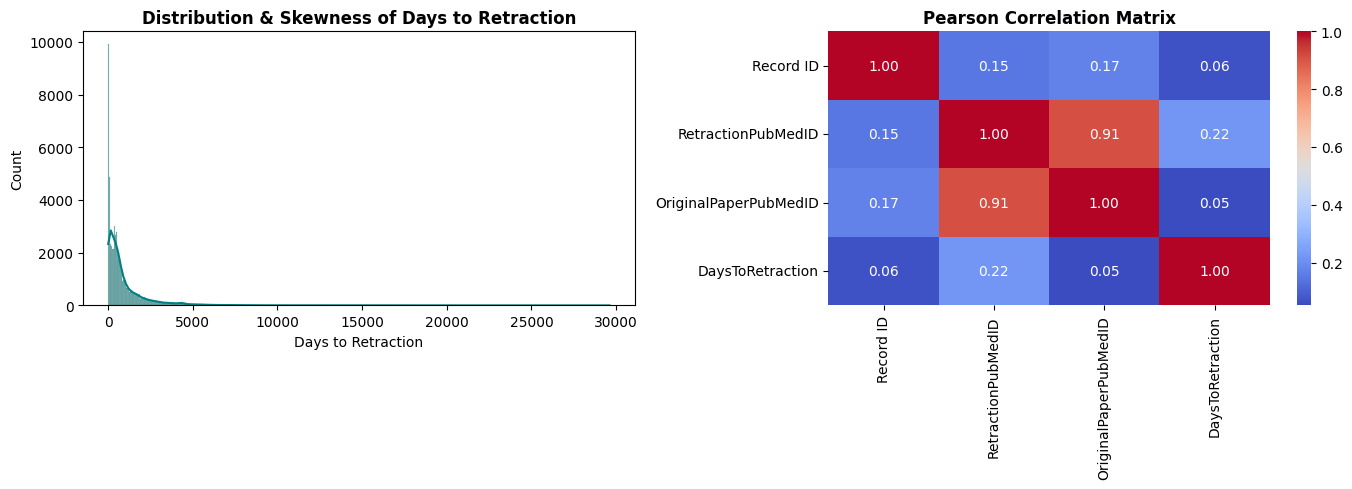

In [10]:
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

#  2. DESCRIPTIVE STATISTICS
# -------------------------------------------------------------
print(" --- DESCRIPTIVE STATISTICS ---")
# Summary for numerical features
num_summary = df.describe().T
print(num_summary[['mean', 'std', 'min', '50%', 'max']])

# Summary for categorical features
cat_summary = df.describe(include=['O']).T
print("\n --- CATEGORICAL SUMMARY ---")
print(cat_summary[['count', 'unique', 'top', 'freq']])


# -------------------------------------------------------------
# 🧪 3. HYPOTHESIS TESTING (Statistical Inference)
# -------------------------------------------------------------

# A. Chi-Square Test of Independence (Categorical vs Categorical)
# Example: Is Paywalled status independent of Retraction/Citation?
if 'Paywalled' in df.columns and 'Subject' in df.columns:
    contingency_table = pd.crosstab(df['Paywalled'], df['Subject'].str.split(';').str[0])
    chi2, p_val_chi2, dof, _ = stats.chi2_contingency(contingency_table)
    
    print("\n🧪 --- CHI-SQUARE TEST ---")
    print(f"Chi2 Statistic: {chi2:.4f}, p-value: {p_val_chi2:.5e}")
    if p_val_chi2 < 0.05:
        print("Result: Statistically Significant association found (p < 0.05)")
    else:
        print("Result: No statistically significant association found")

# B. Two-Sample T-Test / Mann-Whitney U Test (Continuous vs Binary)
# Creates duration feature if dates exist
if 'OriginalPaperDate' in df.columns and 'RetractionDate' in df.columns:
    df['OriginalPaperDate'] = pd.to_datetime(df['OriginalPaperDate'], errors='coerce')
    df['RetractionDate'] = pd.to_datetime(df['RetractionDate'], errors='coerce')
    df['DaysToRetraction'] = (df['RetractionDate'] - df['OriginalPaperDate']).dt.days
    
    clean_df = df.dropna(subset=['DaysToRetraction', 'Paywalled'])
    group_a = clean_df[clean_df['Paywalled'] == 'Yes']['DaysToRetraction']
    group_b = clean_df[clean_df['Paywalled'] == 'No']['DaysToRetraction']
    
    # Mann-Whitney U test (non-parametric alternative to t-test)
    u_stat, p_val_mwu = stats.mannwhitneyu(group_a, group_b)
    print("\n🧪 --- MANN-WHITNEY U TEST ---")
    print(f"U Statistic: {u_stat:.2f}, p-value: {p_val_mwu:.5e}")


# -------------------------------------------------------------
# 📈 4. REGRESSION ANALYSIS (Ordinary Least Squares - OLS)
# -------------------------------------------------------------
# Example regression predicting time to retraction
if 'DaysToRetraction' in df.columns:
    df_reg = df.dropna(subset=['DaysToRetraction']).copy()
    
    # Define features
    X = pd.get_dummies(df_reg[['Paywalled']], drop_first=True, dtype=float)
    X = sm.add_constant(X)
    y = df_reg['DaysToRetraction']
    
    model = sm.OLS(y, X).fit()
    print("\n📊 --- OLS REGRESSION SUMMARY ---")
    print(model.summary().tables[1])


# -------------------------------------------------------------
#  5. STATISTICAL VISUALIZATIONS
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Visualization 1: Distribution Analysis with KDE & Normality
if 'DaysToRetraction' in df.columns:
    sns.histplot(df_reg['DaysToRetraction'], kde=True, ax=axes[0], color='teal')
    axes[0].set_title("Distribution & Skewness of Days to Retraction", fontweight='bold')
    axes[0].set_xlabel("Days to Retraction")

# Visualization 2: Correlation Heatmap (for numerical variables)
num_cols = df.select_dtypes(include=[np.number]).columns
if len(num_cols) > 1:
    corr_matrix = df[num_cols].corr()
    sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", ax=axes[1])
    axes[1].set_title("Pearson Correlation Matrix", fontweight='bold')
else:
    # Fallback plot for Paywalled breakdown
    sns.countplot(data=df, x='Paywalled', ax=axes[1], palette='Set2')
    axes[1].set_title("Paywalled Distribution", fontweight='bold')

plt.tight_layout()
plt.show()

In [11]:
df['OriginalPaperDate'] = pd.to_datetime(df['OriginalPaperDate'], errors='coerce')
df['RetractionDate'] = pd.to_datetime(df['RetractionDate'], errors='coerce')

# Filter out null date rows
df_core = df.dropna(subset=['OriginalPaperDate', 'RetractionDate']).copy()

# -------------------------------------------------------------
# FEATURE 1 & 2: Time-to-Retraction (DaysToRetraction & Years)
# -------------------------------------------------------------
df_core['DaysToRetraction'] = (df_core['RetractionDate'] - df_core['OriginalPaperDate']).dt.days
df_core['YearsToRetraction'] = (df_core['DaysToRetraction'] / 365.25).round(2)

# Remove negative date anomalies
df_core = df_core[df_core['DaysToRetraction'] >= 0]

print(" --- Time-to-Retraction Metrics ---")
print(f" Median Time: {df_core['DaysToRetraction'].median():.0f} days (~{df_core['YearsToRetraction'].median():.2f} years)")
print(f" Mean Time: {df_core['DaysToRetraction'].mean():.0f} days (~{df_core['YearsToRetraction'].mean():.2f} years)\n")

# -------------------------------------------------------------
#  FEATURE 3: RetractionNature Analysis
# -------------------------------------------------------------
print(" --- RetractionNature Frequency ---")
print(df_core['RetractionNature'].value_counts())
print("\n")

# -------------------------------------------------------------
#  FEATURE 4: Exploded Reason Analysis (Top 10 Reasons)
# -------------------------------------------------------------
# Explode semicolon-separated multi-value text
reasons_exploded = df_core['Reason'].dropna().str.split(';').explode().str.strip()
reasons_exploded = reasons_exploded[reasons_exploded != '']

print(" --- Top 10 Core Retraction Reasons ---")
print(reasons_exploded.value_counts().head(10))
print("\n")

# -------------------------------------------------------------
#  FEATURE 5: Exploded Subject Analysis (Top 10 Subjects)
# -------------------------------------------------------------
# Explode semicolon-separated subject fields
subjects_exploded = df_core['Subject'].dropna().str.split(';').explode().str.strip()
subjects_exploded = subjects_exploded[subjects_exploded != '']

print(" --- Top 10 Core Disciplines/Subjects ---")
print(subjects_exploded.value_counts().head(10))

 --- Time-to-Retraction Metrics ---
 Median Time: 499 days (~1.37 years)
 Mean Time: 959 days (~2.63 years)

 --- RetractionNature Frequency ---
RetractionNature
Retraction               66450
Expression of concern     3587
Correction                1506
Reinstatement              160
Name: count, dtype: int64


 --- Top 10 Core Retraction Reasons ---
Reason
Investigation by Journal/Publisher                  31709
Unreliable Results and/or Conclusions               21809
Investigation by Third Party                        17646
Concerns/Issues about Data                          15852
Concerns/Issues about Referencing/Attributions      15251
Notice - Limited or No Information                  12109
Paper Mill                                          11797
Concerns/Issues about Peer Review                   11679
Compromised Peer Review                             11510
Concerns/Issues about Results and/or Conclusions     9962
Name: count, dtype: int64


 --- Top 10 Core Disciplines/Su

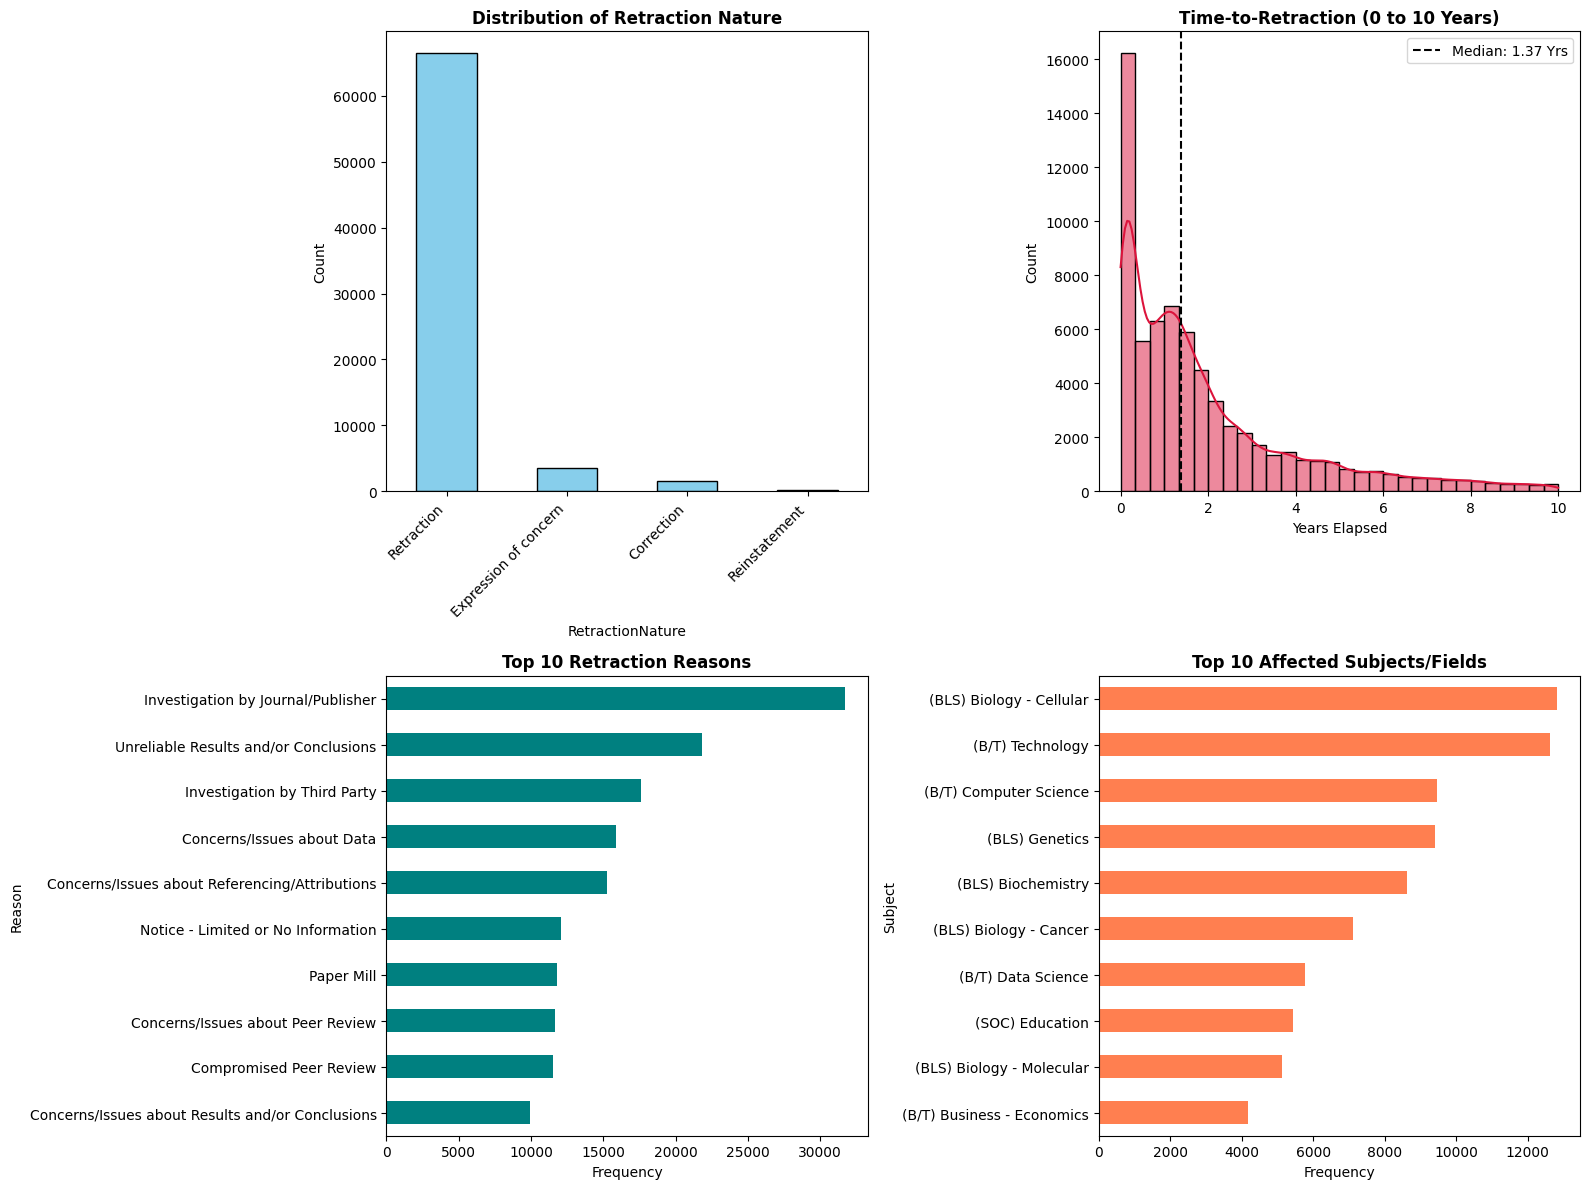

In [12]:
plt.figure(figsize=(16, 12))

# Subplot 1: Retraction Nature
plt.subplot(2, 2, 1)
df_core['RetractionNature'].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Distribution of Retraction Nature', fontsize=12, fontweight='bold')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')

# Subplot 2: Time-to-Retraction Distribution (0-10 Years)
plt.subplot(2, 2, 2)
sns.histplot(df_core[df_core['YearsToRetraction'] <= 10]['YearsToRetraction'], bins=30, kde=True, color='crimson')
plt.axvline(df_core['YearsToRetraction'].median(), color='black', linestyle='--', label=f"Median: {df_core['YearsToRetraction'].median()} Yrs")
plt.title('Time-to-Retraction (0 to 10 Years)', fontsize=12, fontweight='bold')
plt.xlabel('Years Elapsed')
plt.legend()

# Subplot 3: Top 10 Retraction Reasons
plt.subplot(2, 2, 3)
reasons_exploded.value_counts().head(10).plot(kind='barh', color='teal').invert_yaxis()
plt.title('Top 10 Retraction Reasons', fontsize=12, fontweight='bold')
plt.xlabel('Frequency')

# Subplot 4: Top 10 Subjects
plt.subplot(2, 2, 4)
subjects_exploded.value_counts().head(10).plot(kind='barh', color='coral').invert_yaxis()
plt.title('Top 10 Affected Subjects/Fields', fontsize=12, fontweight='bold')
plt.xlabel('Frequency')

plt.tight_layout()
plt.show()

 --- Top 5 Publishers ---
Publisher
Hindawi                                                    11524
IEEE: Institute of Electrical and Electronics Engineers    10098
Elsevier                                                    7282
Springer                                                    5211
Wiley                                                       4293
Name: count, dtype: int64

 --- Top 5 Journals ---
Journal
Journal of Intelligent & Fuzzy Systems                                            1607
PLoS One                                                                          1490
2011 International Conference on E-Business and E-Government (ICEE)               1280
2011 5th International Conference on Bioinformatics and Biomedical Engineering    1084
Journal of Healthcare Engineering                                                 1074
Name: count, dtype: int64

 --- Top 5 Countries ---
Country
China            37929
United States     7438
India             6351
Russia          

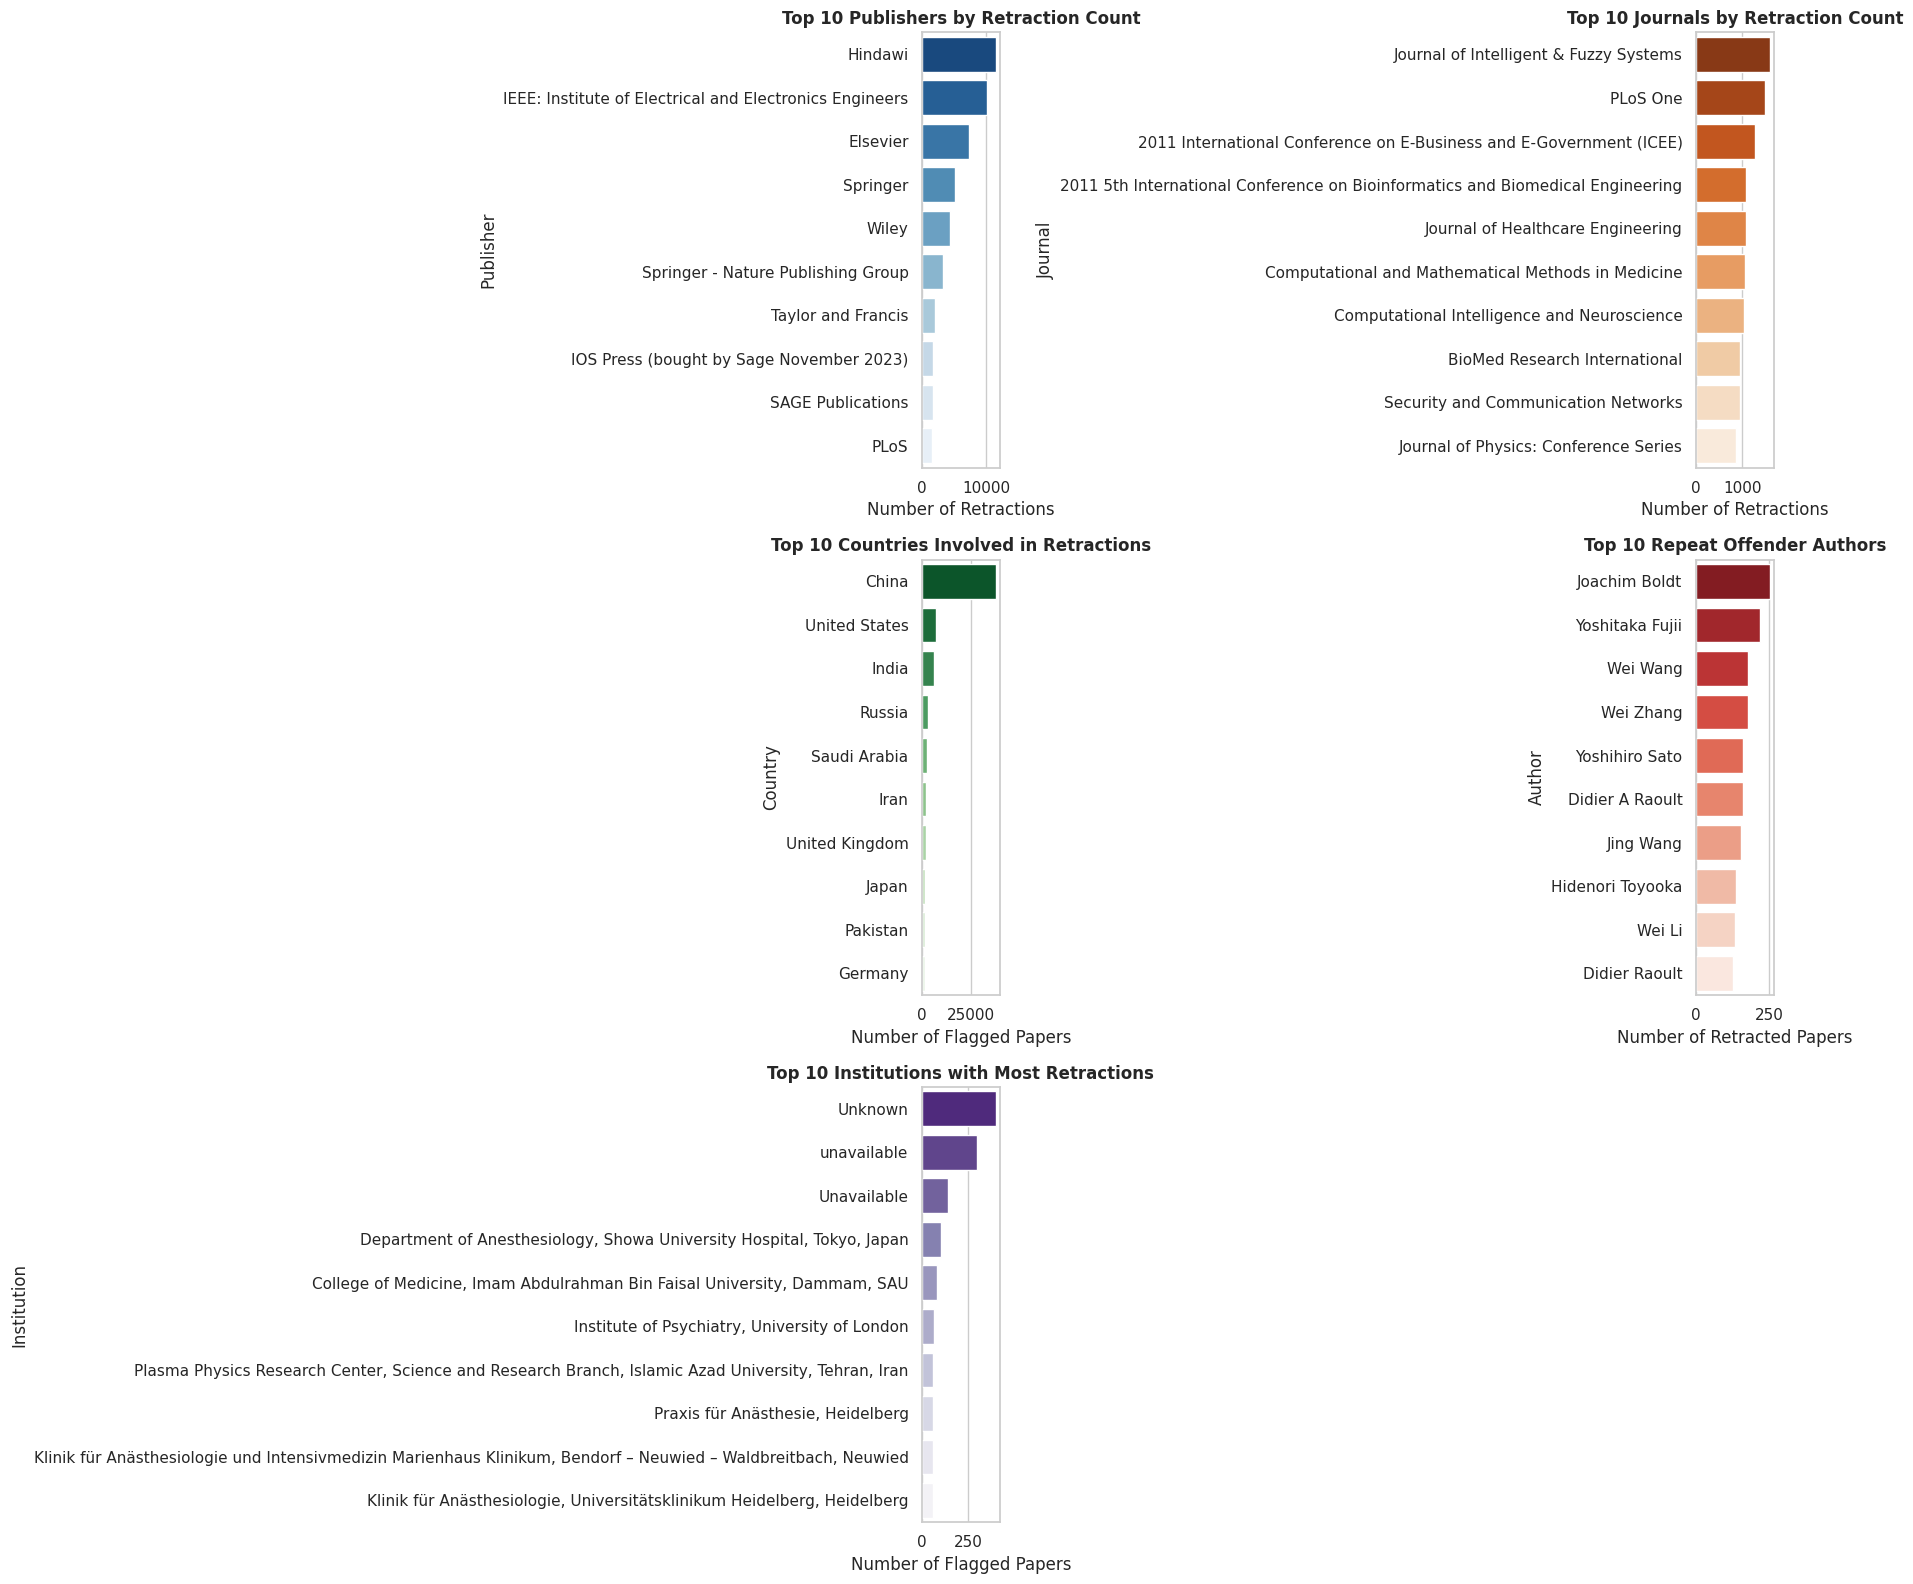

In [13]:
sns.set_theme(style="whitegrid")


# Remove empty column if present
if 'Unnamed: 20' in df.columns:
    df = df.drop(columns=['Unnamed: 20'])

# -------------------------------------------------------------
#  DATA PREPARATION & EXPLOSION FOR MULTI-ENTITY COLUMNS
# -------------------------------------------------------------

# Explode semicolon-separated Authors (to count individual authors accurately)
authors_exploded = df['Author'].dropna().str.split(';').explode().str.strip()
authors_exploded = authors_exploded[authors_exploded != '']

# Explode semicolon-separated Institutions
institutions_exploded = df['Institution'].dropna().str.split(';').explode().str.strip()
institutions_exploded = institutions_exploded[institutions_exploded != '']

# Explode semicolon-separated Countries
countries_exploded = df['Country'].dropna().str.split(';').explode().str.strip()
countries_exploded = countries_exploded[countries_exploded != '']

# Single-value entities (Journal & Publisher)
top_journals = df['Journal'].value_counts().head(10)
top_publishers = df['Publisher'].value_counts().head(10)
top_countries = countries_exploded.value_counts().head(10)
top_authors = authors_exploded.value_counts().head(10)
top_institutions = institutions_exploded.value_counts().head(10)

# -------------------------------------------------------------
# CONSOLE SUMMARY PRINTING
# -------------------------------------------------------------
print(" --- Top 5 Publishers ---")
print(top_publishers.head(5))
print("\n --- Top 5 Journals ---")
print(top_journals.head(5))
print("\n --- Top 5 Countries ---")
print(top_countries.head(5))
print("\n --- Top 5 Authors (Repeat Offenders) ---")
print(top_authors.head(5))
print("\n --- Top 5 Institutions ---")
print(top_institutions.head(5))

# -------------------------------------------------------------
#  VISUALIZATION GRID (5 High-Impact Subplots)
# -------------------------------------------------------------
fig, axes = plt.subplots(3, 2, figsize=(18, 16))

# Plot 1: Top 10 Publishers
sns.barplot(x=top_publishers.values, y=top_publishers.index, ax=axes[0, 0], palette="Blues_r")
axes[0, 0].set_title("Top 10 Publishers by Retraction Count", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Number of Retractions")

# Plot 2: Top 10 Journals
sns.barplot(x=top_journals.values, y=top_journals.index, ax=axes[0, 1], palette="Oranges_r")
axes[0, 1].set_title("Top 10 Journals by Retraction Count", fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel("Number of Retractions")

# Plot 3: Top 10 Countries
sns.barplot(x=top_countries.values, y=top_countries.index, ax=axes[1, 0], palette="Greens_r")
axes[1, 0].set_title("Top 10 Countries Involved in Retractions", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Number of Flagged Papers")

# Plot 4: Top 10 Authors (Repeat Offenders)
sns.barplot(x=top_authors.values, y=top_authors.index, ax=axes[1, 1], palette="Reds_r")
axes[1, 1].set_title("Top 10 Repeat Offender Authors", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("Number of Retracted Papers")

# Plot 5: Top 10 Institutions
sns.barplot(x=top_institutions.values, y=top_institutions.index, ax=axes[2, 0], palette="Purples_r")
axes[2, 0].set_title("Top 10 Institutions with Most Retractions", fontsize=12, fontweight='bold')
axes[2, 0].set_xlabel("Number of Flagged Papers")

# Remove unused 6th subplot
fig.delaxes(axes[2, 1])

plt.tight_layout()
plt.show()

 --- Paywalled Status Distribution ---
           Count  Percentage (%)
Paywalled                       
No         69837           97.04
Yes         1640            2.28
NaN          264            0.37
Unknown      227            0.32

 --- Top 10 Article Types ---
ArticleType
Research Article               48877
Conference Abstract/Paper      14116
Clinical Study                  3122
Review Article                  2832
Meta-Analysis                    906
Case Report                      890
Book Chapter/Reference Work      585
Letter                           539
Article in Press                 525
Commentary/Editorial             462
Name: count, dtype: int64

 --- DOI Linkage Coverage ---
            Metric  Present Count  Missing Count  Coverage (%)
Original Paper DOI          69180           2788         96.13
    Retraction DOI          71220            748         98.96


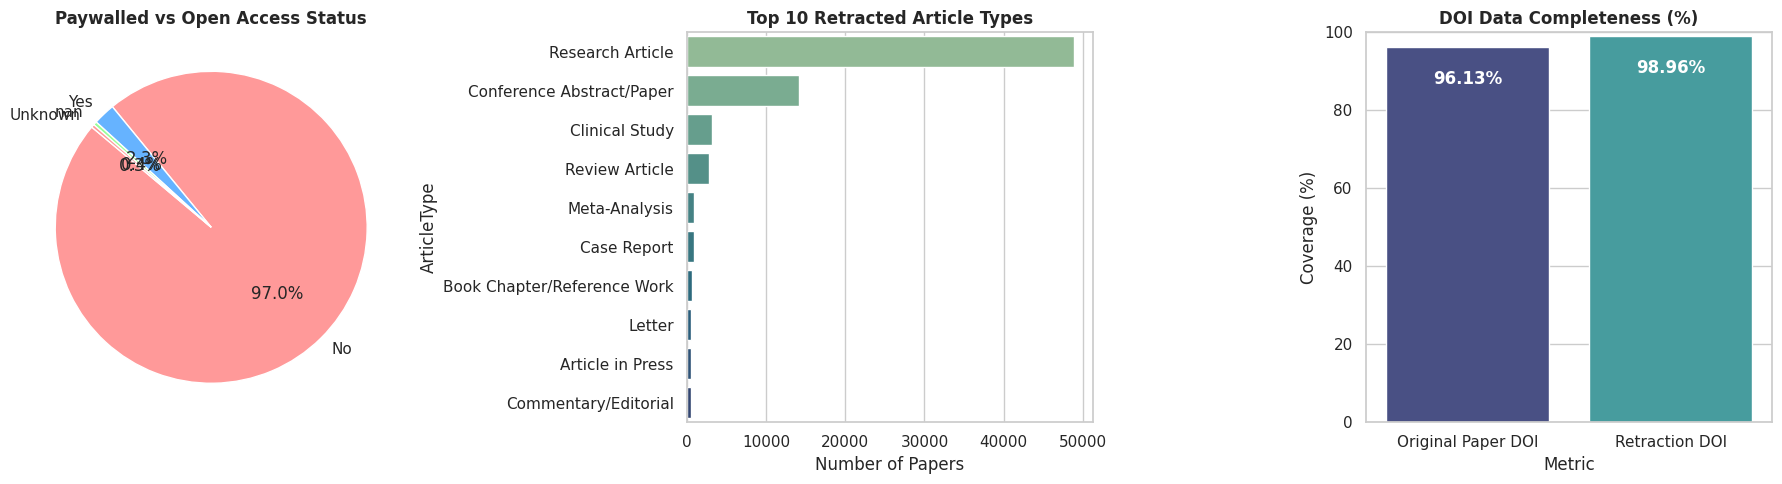

In [14]:
# 1. Paywalled Status Distribution
paywalled_counts = df['Paywalled'].value_counts(dropna=False)
paywalled_pct = df['Paywalled'].value_counts(normalize=True, dropna=False) * 100

# 2. Explode ArticleType (Handling multi-value types separated by semicolons)
article_types_exploded = df['ArticleType'].dropna().str.split(';').explode().str.strip()
article_types_exploded = article_types_exploded[article_types_exploded != '']
top_article_types = article_types_exploded.value_counts().head(10)

# 3. DOI Coverage & Linkage Completeness
doi_summary = pd.DataFrame({
    'Metric': ['Original Paper DOI', 'Retraction DOI'],
    'Present Count': [df['OriginalPaperDOI'].notnull().sum(), df['RetractionDOI'].notnull().sum()],
    'Missing Count': [df['OriginalPaperDOI'].isnull().sum(), df['RetractionDOI'].isnull().sum()],
    'Coverage (%)': [
        (df['OriginalPaperDOI'].notnull().sum() / len(df) * 100).round(2),
        (df['RetractionDOI'].notnull().sum() / len(df) * 100).round(2)
    ]
})

# -------------------------------------------------------------
# 📊 CONSOLE SUMMARY
# -------------------------------------------------------------
print(" --- Paywalled Status Distribution ---")
print(pd.DataFrame({'Count': paywalled_counts, 'Percentage (%)': paywalled_pct.round(2)}))
print("\n --- Top 10 Article Types ---")
print(top_article_types)
print("\n --- DOI Linkage Coverage ---")
print(doi_summary.to_string(index=False))

# -------------------------------------------------------------
#  VISUALIZATION GRID (3 Focused Subplots)
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subplot 1: Paywalled Status (Pie Chart)
colors = ['#ff9999', '#66b3ff', '#99ff99']
axes[0].pie(paywalled_counts, labels=paywalled_counts.index, autopct='%1.1f%%', startangle=140, colors=colors)
axes[0].set_title("Paywalled vs Open Access Status", fontsize=12, fontweight='bold')

# Subplot 2: Top 10 Article Types (Horizontal Bar Chart)
sns.barplot(x=top_article_types.values, y=top_article_types.index, ax=axes[1], palette="crest")
axes[1].set_title("Top 10 Retracted Article Types", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Number of Papers")

# Subplot 3: DOI Completeness Comparison
sns.barplot(data=doi_summary, x='Metric', y='Coverage (%)', ax=axes[2], palette="mako")
axes[2].set_title("DOI Data Completeness (%)", fontsize=12, fontweight='bold')
axes[2].set_ylim(0, 100)
for p in axes[2].patches:
    axes[2].annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() - 8),
                     ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

 --- Secondary Features Missingness Summary ---
              Feature  Available Count  Missing Count  Missing (%)
                 URLS            39585          32383        45.00
                Notes            20119          51849        72.04
   RetractionPubMedID            66567           5401         7.50
OriginalPaperPubMedID            66584           5384         7.48

 --- Notes Text Character/Word Count Stats (NLP Utility) ---
count    20119.00
mean         6.61
std          5.96
min          1.00
25%          3.00
50%          4.00
75%          8.00
max        172.00
Name: Notes, dtype: float64

 --- PubMed ID Coverage Comparison ---
Overall Dataset PubMed Coverage: 92.52%
Medical/Biology Domain PubMed Coverage: 98.58%


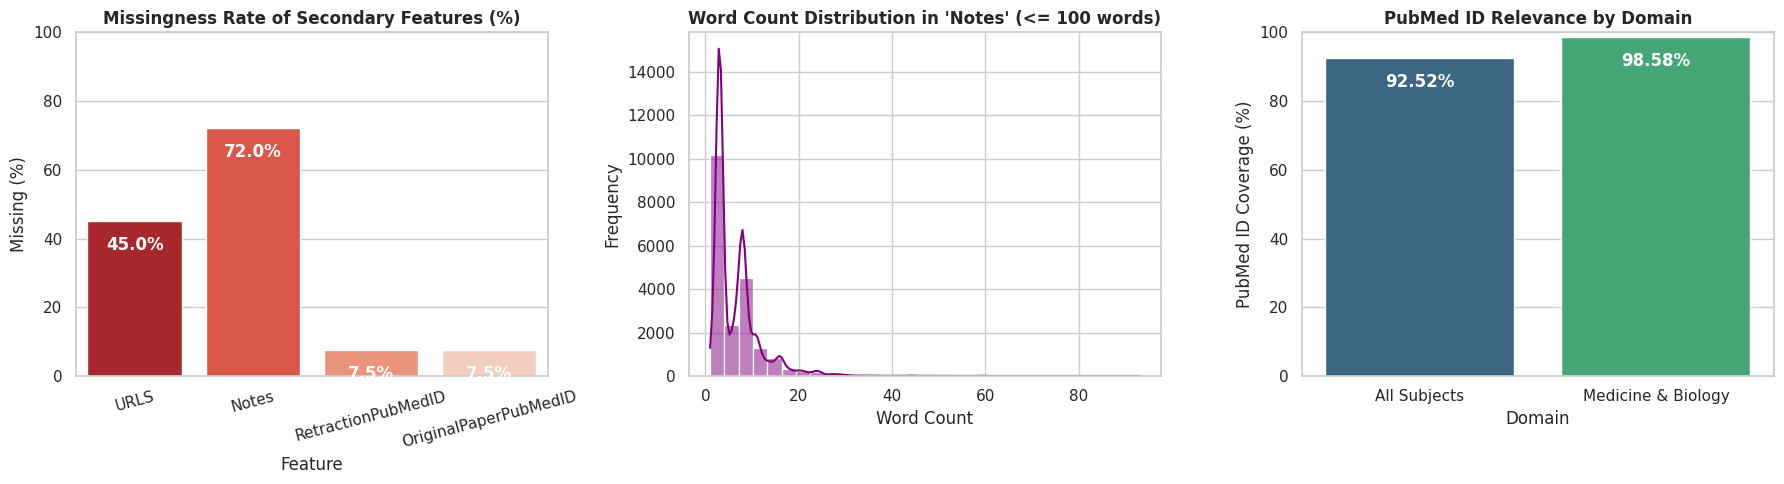

In [15]:
# 1. Missingness Breakdown
sec_features = ['URLS', 'Notes', 'RetractionPubMedID', 'OriginalPaperPubMedID']
missing_summary = pd.DataFrame({
    'Feature': sec_features,
    'Available Count': [df[col].notnull().sum() for col in sec_features],
    'Missing Count': [df[col].isnull().sum() for col in sec_features],
    'Missing (%)': [(df[col].isnull().sum() / len(df) * 100).round(2) for col in sec_features]
})

# 2. Text Analysis on 'Notes' Feature (for NLP Potential)
notes_present = df['Notes'].dropna()
notes_length = notes_present.apply(lambda x: len(str(x).split()))

# 3. Medical Domain Filter for PubMed ID Evaluation
# Checks if PubMed coverage is higher specifically in Medicine/Biology papers
is_medical = df['Subject'].dropna().str.contains('Medicine|Biology|Health', case=False, regex=True)
med_df = df[df['Subject'].notnull() & is_medical]

pubmed_overall_coverage = (df['OriginalPaperPubMedID'].notnull().sum() / len(df)) * 100
pubmed_medical_coverage = (med_df['OriginalPaperPubMedID'].notnull().sum() / len(med_df)) * 100

# -------------------------------------------------------------
#  CONSOLE SUMMARY
# -------------------------------------------------------------
print(" --- Secondary Features Missingness Summary ---")
print(missing_summary.to_string(index=False))

print("\n --- Notes Text Character/Word Count Stats (NLP Utility) ---")
print(notes_length.describe().round(2))

print("\n --- PubMed ID Coverage Comparison ---")
print(f"Overall Dataset PubMed Coverage: {pubmed_overall_coverage:.2f}%")
print(f"Medical/Biology Domain PubMed Coverage: {pubmed_medical_coverage:.2f}%")

# -------------------------------------------------------------
#  VISUALIZATION GRID (3 Focused Subplots)
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subplot 1: Missing Data Percentage
sns.barplot(data=missing_summary, x='Feature', y='Missing (%)', ax=axes[0], palette="Reds_r")
axes[0].set_title("Missingness Rate of Secondary Features (%)", fontsize=12, fontweight='bold')
axes[0].set_ylim(0, 100)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=15)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() - 7),
                     ha='center', va='center', color='white', fontweight='bold')

# Subplot 2: Word Count Distribution of Available 'Notes'
sns.histplot(notes_length[notes_length <= 100], bins=30, kde=True, ax=axes[1], color="purple")
axes[1].set_title("Word Count Distribution in 'Notes' (<= 100 words)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Word Count")
axes[1].set_ylabel("Frequency")

# Subplot 3: PubMed ID Utility (Overall vs Medical Domain)
coverage_data = pd.DataFrame({
    'Domain': ['All Subjects', 'Medicine & Biology'],
    'PubMed ID Coverage (%)': [pubmed_overall_coverage, pubmed_medical_coverage]
})
sns.barplot(data=coverage_data, x='Domain', y='PubMed ID Coverage (%)', ax=axes[2], palette="viridis")
axes[2].set_title("PubMed ID Relevance by Domain", fontsize=12, fontweight='bold')
axes[2].set_ylim(0, 100)
for p in axes[2].patches:
    axes[2].annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height() - 7),
                     ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

# Temporal & Survival Analysis

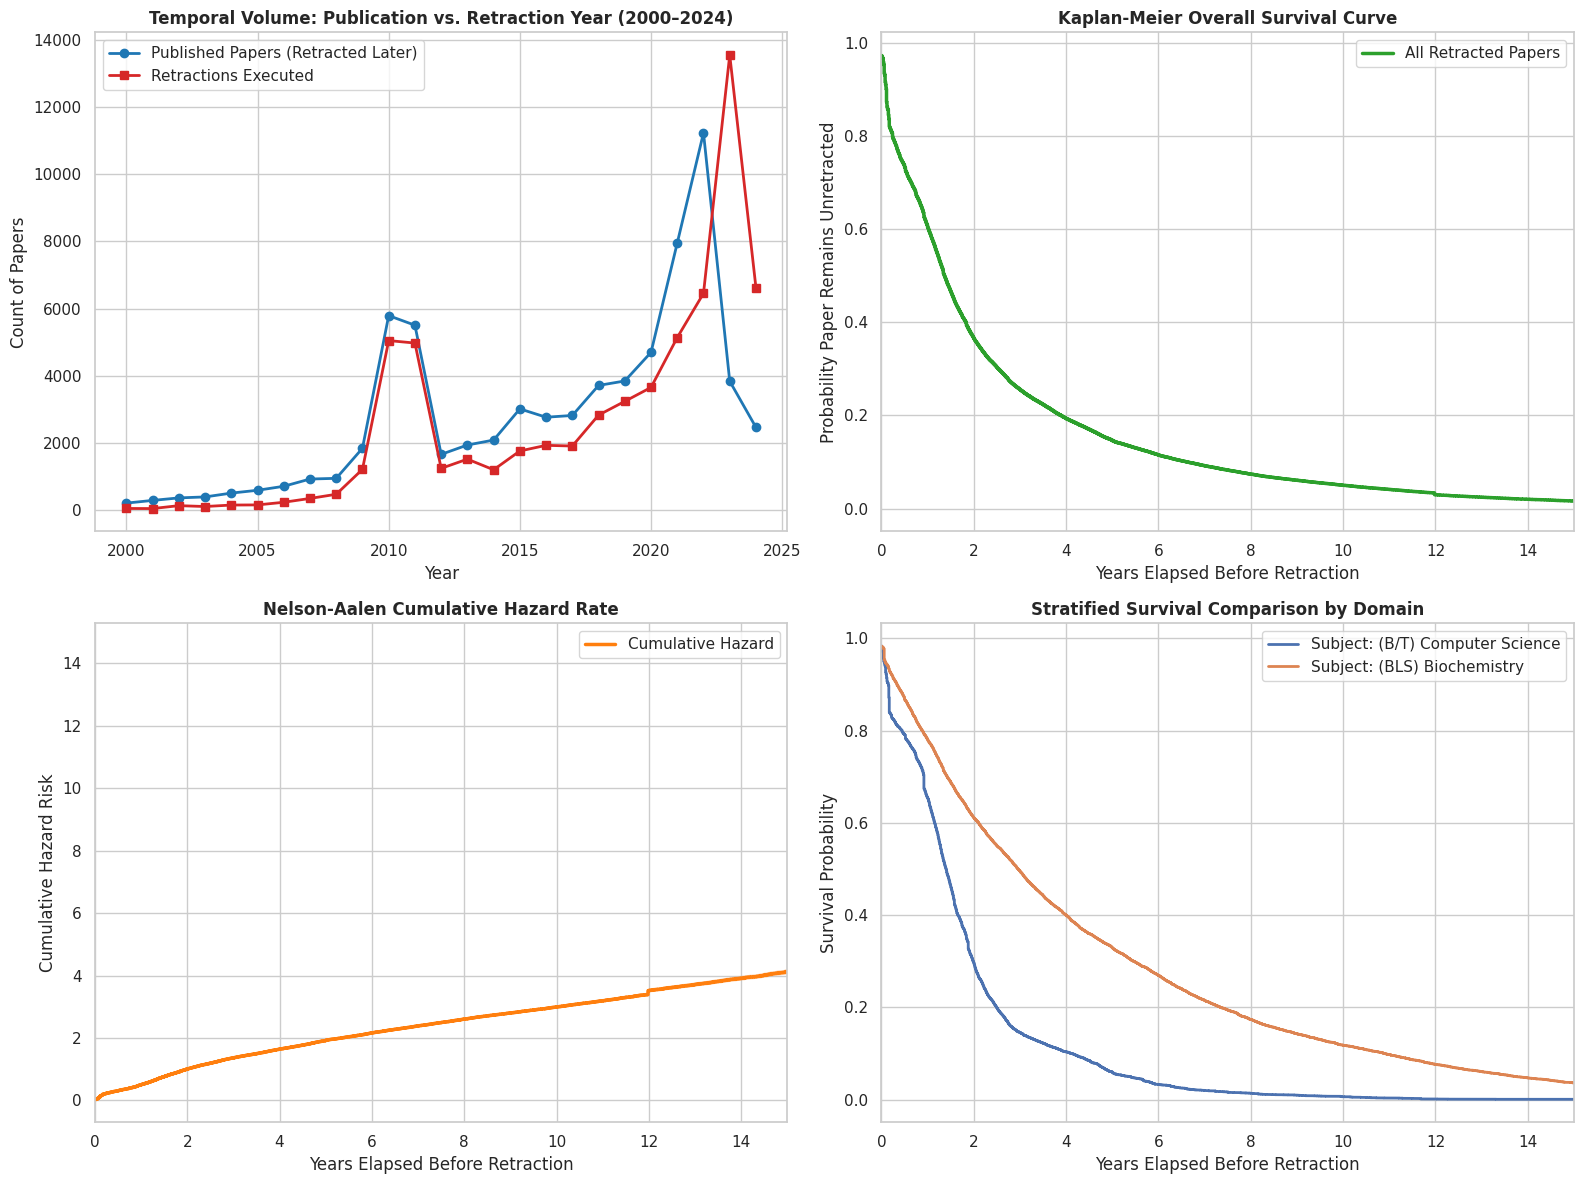

 --- Kaplan-Meier Survival Summary ---
Median Survival Time (Years): 1.37 years
5-Year Survival Probability: 0.1459 (14.59%)
10-Year Survival Probability: 0.0499 (4.99%)


In [16]:
from lifelines import KaplanMeierFitter, NelsonAalenFitter

df['OriginalPaperDate'] = pd.to_datetime(df['OriginalPaperDate'], errors='coerce')
df['RetractionDate'] = pd.to_datetime(df['RetractionDate'], errors='coerce')

# Drop missing date entries
df_clean = df.dropna(subset=['OriginalPaperDate', 'RetractionDate']).copy()

# Feature Engineering: Durations and Years
df_clean['DaysToRetraction'] = (df_clean['RetractionDate'] - df_clean['OriginalPaperDate']).dt.days
df_clean['YearsToRetraction'] = (df_clean['DaysToRetraction'] / 365.25).round(2)
df_clean['PubYear'] = df_clean['OriginalPaperDate'].dt.year
df_clean['RetractionYear'] = df_clean['RetractionDate'].dt.year

# Filter out non-sensical negative duration anomalies
df_survival = df_clean[df_clean['DaysToRetraction'] >= 0].copy()

# -------------------------------------------------------------
# ⏳ 1. TEMPORAL TRENDS ANALYSIS
# -------------------------------------------------------------
# Filter years between 2000 and current year for clean plotting
pub_trends = df_survival[(df_survival['PubYear'] >= 2000) & (df_survival['PubYear'] <= 2024)]['PubYear'].value_counts().sort_index()
ret_trends = df_survival[(df_survival['RetractionYear'] >= 2000) & (df_survival['RetractionYear'] <= 2024)]['RetractionYear'].value_counts().sort_index()

# -------------------------------------------------------------
# 📈 2. SURVIVAL ANALYSIS DATA SETUP
# -------------------------------------------------------------
# Event = 1 (Retraction observed)
df_survival['Event'] = 1
T = df_survival['YearsToRetraction']
E = df_survival['Event']

# Initialize Lifelines Fitters
kmf = KaplanMeierFitter()
kmf.fit(T, event_observed=E, label='All Retracted Papers')

naf = NelsonAalenFitter()
naf.fit(T, event_observed=E, label='Cumulative Hazard')

# Top 2 Disciplines for Stratified Survival Comparison
df_survival['PrimarySubject'] = df_survival['Subject'].str.split(';').str[0].str.strip()
top_subjects = df_survival['PrimarySubject'].value_counts().head(2).index.tolist()

# -------------------------------------------------------------
# 🎨 VISUALIZATION GRID (4 High-Impact Plots)
# -------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Subplot 1: Temporal Trend (Publication vs Retraction Year)
axes[0, 0].plot(pub_trends.index, pub_trends.values, marker='o', label='Published Papers (Retracted Later)', color='#1f77b4', linewidth=2)
axes[0, 0].plot(ret_trends.index, ret_trends.values, marker='s', label='Retractions Executed', color='#d62728', linewidth=2)
axes[0, 0].set_title("Temporal Volume: Publication vs. Retraction Year (2000–2024)", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Year")
axes[0, 0].set_ylabel("Count of Papers")
axes[0, 0].legend()

# Subplot 2: Kaplan-Meier Survival Curve (Survival Probability)
kmf.plot_survival_function(ax=axes[0, 1], color='#2ca02c', ci_show=True, linewidth=2.5)
axes[0, 1].set_title("Kaplan-Meier Overall Survival Curve", fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel("Years Elapsed Before Retraction")
axes[0, 1].set_ylabel("Probability Paper Remains Unretracted")
axes[0, 1].set_xlim(0, 15) # Focused on 0 to 15 years timeline

# Subplot 3: Cumulative Hazard Rate Curve
naf.plot_cumulative_hazard(ax=axes[1, 0], color='#ff7f0e', ci_show=True, linewidth=2.5)
axes[1, 0].set_title("Nelson-Aalen Cumulative Hazard Rate", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Years Elapsed Before Retraction")
axes[1, 0].set_ylabel("Cumulative Hazard Risk")
axes[1, 0].set_xlim(0, 15)

# Subplot 4: Stratified Survival Comparison by Top 2 Subjects
for subject in top_subjects:
    sub_mask = df_survival['PrimarySubject'] == subject
    kmf_sub = KaplanMeierFitter()
    kmf_sub.fit(T[sub_mask], event_observed=E[sub_mask], label=f"Subject: {subject}")
    kmf_sub.plot_survival_function(ax=axes[1, 1], ci_show=False, linewidth=2)

axes[1, 1].set_title("Stratified Survival Comparison by Domain", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("Years Elapsed Before Retraction")
axes[1, 1].set_ylabel("Survival Probability")
axes[1, 1].set_xlim(0, 15)
axes[1, 1].legend()

plt.tight_layout()
plt.show()

# Print Key Survival Summary Metrics
print(" --- Kaplan-Meier Survival Summary ---")
print(f"Median Survival Time (Years): {kmf.median_survival_time_:.2f} years")
print(f"5-Year Survival Probability: {kmf.predict(5):.4f} ({kmf.predict(5)*100:.2f}%)")
print(f"10-Year Survival Probability: {kmf.predict(10):.4f} ({kmf.predict(10)*100:.2f}%)")

# Text & Co-occurrence Mining 


 --- Classification Breakdown ---
Reason
Misconduct / Fraud           25126
Both (Misconduct & Error)    23100
Other / Administrative       16792
Honest Error / Unreliable     6686
Name: count, dtype: int64




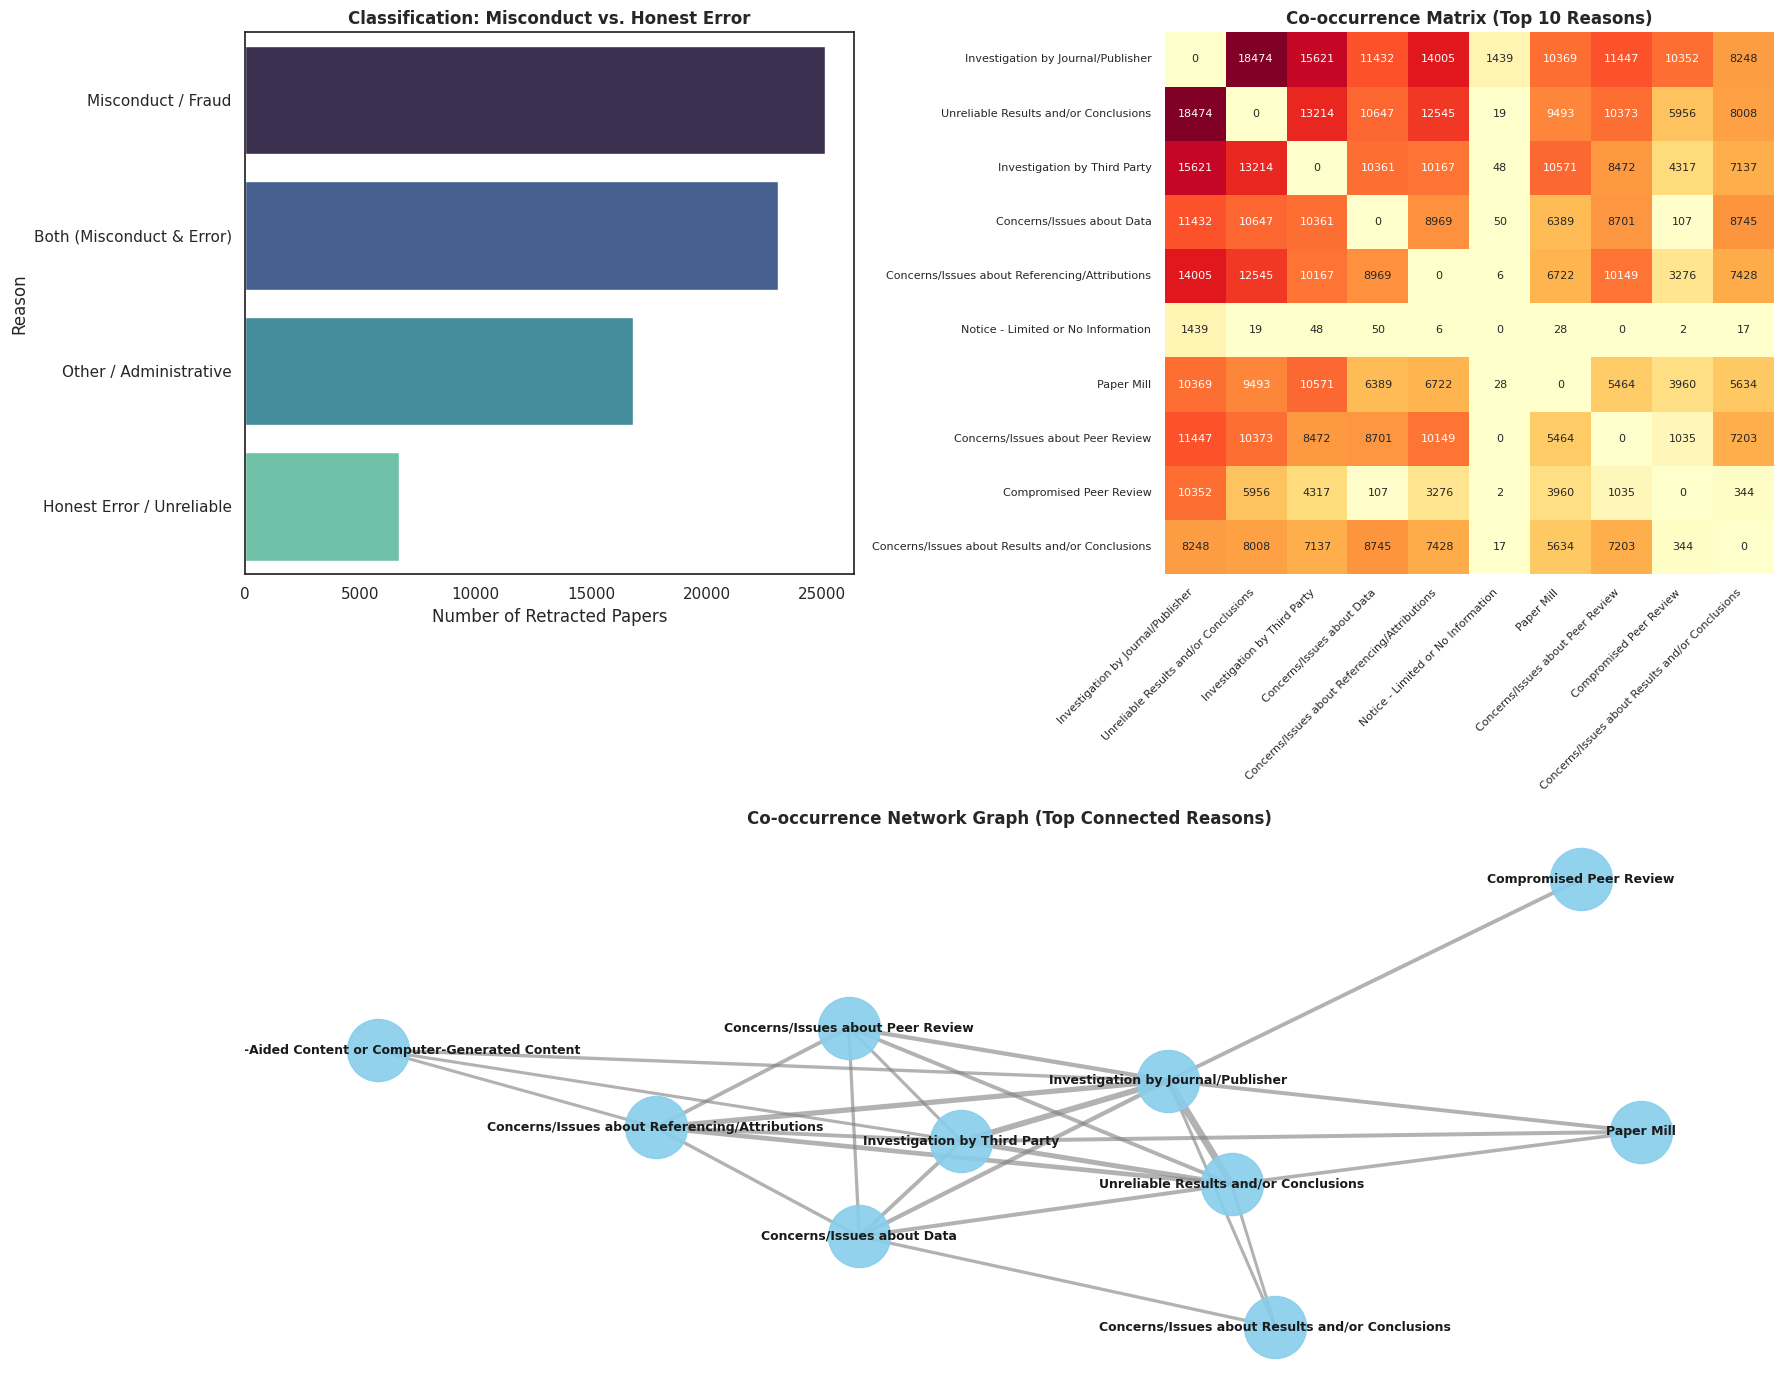

In [17]:
import itertools
import networkx as nx
from collections import Counter
# Set visual aesthetic
sns.set_theme(style="white")

# Clean and split reasons per paper into distinct lists
reasons_lists = (
    df['Reason']
    .dropna()
    .apply(lambda x: [r.strip() for r in str(x).split(';') if r.strip()])
)

# -------------------------------------------------------------
# 🎯 1. SUB-REASON EXTRACTION: Misconduct vs. Honest Error
# -------------------------------------------------------------
misconduct_keywords = [
    'Plagiarism', 'Falsification', 'Fabrication', 'Duplication', 
    'Fake', 'Fraud', 'Forgery', 'Manipulation', 'Investigation', 'Misconduct'
]
honest_error_keywords = [
    'Error', 'Unreliable', 'Contamination', 'Mistake', 
    'Unable to Reproduce', 'Inconsistency'
]

def classify_reason(reason_list):
    text = " ".join(reason_list)
    has_misconduct = any(kw.lower() in text.lower() for kw in misconduct_keywords)
    has_error = any(kw.lower() in text.lower() for kw in honest_error_keywords)
    
    if has_misconduct and has_error:
        return 'Both (Misconduct & Error)'
    elif has_misconduct:
        return 'Misconduct / Fraud'
    elif has_error:
        return 'Honest Error / Unreliable'
    else:
        return 'Other / Administrative'

classification_counts = reasons_lists.apply(classify_reason).value_counts()

print(" --- Classification Breakdown ---")
print(classification_counts)
print("\n")

# -------------------------------------------------------------
# 🔗 . CO-OCCURRENCE MATRIX (Top 10 Reasons)
# -------------------------------------------------------------
# Find top 10 individual reasons
all_individual_reasons = [r for sublist in reasons_lists for r in sublist]
top_10_reasons = [r for r, c in Counter(all_individual_reasons).most_common(10)]

# Build co-occurrence matrix
co_matrix = pd.DataFrame(0, index=top_10_reasons, columns=top_10_reasons)

for r_list in reasons_lists:
    # Filter for top 10
    filtered = [r for r in set(r_list) if r in top_10_reasons]
    for r1, r2 in itertools.combinations(filtered, 2):
        co_matrix.loc[r1, r2] += 1
        co_matrix.loc[r2, r1] += 1

# -------------------------------------------------------------
# 🕸️ 3. NETWORK GRAPH GENERATION (using networkx)
# -------------------------------------------------------------
# Generate pairs across all reasons
pair_counts = Counter()
for r_list in reasons_lists:
    unique_reasons = sorted(list(set(r_list)))
    if len(unique_reasons) > 1:
        for pair in itertools.combinations(unique_reasons, 2):
            pair_counts[pair] += 1

# Take top 25 co-occurring pairs for graph clarity
top_pairs = pair_counts.most_common(25)

G = nx.Graph()
for (node1, node2), weight in top_pairs:
    G.add_edge(node1, node2, weight=weight)

# -------------------------------------------------------------
#  VISUALIZATION GRID
# -------------------------------------------------------------
fig = plt.figure(figsize=(18, 14))

# Subplot 1: Misconduct vs Honest Error Classification
ax1 = plt.subplot2grid((2, 2), (0, 0))
sns.barplot(x=classification_counts.values, y=classification_counts.index, ax=ax1, palette="mako")
ax1.set_title("Classification: Misconduct vs. Honest Error", fontsize=12, fontweight='bold')
ax1.set_xlabel("Number of Retracted Papers")

# Subplot 2: Co-occurrence Heatmap Matrix
ax2 = plt.subplot2grid((2, 2), (0, 1))
sns.heatmap(co_matrix, annot=True, fmt="d", cmap="YlOrRd", ax=ax2, cbar=False, annot_kws={"size": 8})
ax2.set_title("Co-occurrence Matrix (Top 10 Reasons)", fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)

# Subplot 3: Network Graph Visualization (FIXED UNPACKING)
ax3 = plt.subplot2grid((2, 2), (1, 0), colspan=2)
pos = nx.spring_layout(G, k=0.8, seed=42)

# Correctly extract maximum weight from top_pairs
max_weight = max([weight for _, weight in top_pairs])
weights = [G[u][v]['weight'] / max_weight * 5 for u, v in G.edges()]

nx.draw_networkx_nodes(G, pos, node_size=2000, node_color='skyblue', alpha=0.9, ax=ax3)
nx.draw_networkx_edges(G, pos, width=weights, edge_color='gray', alpha=0.6, ax=ax3)
nx.draw_networkx_labels(G, pos, font_size=9, font_family='sans-serif', font_weight='bold', ax=ax3)

ax3.set_title("Co-occurrence Network Graph (Top Connected Reasons)", fontsize=12, fontweight='bold')
ax3.axis('off')

plt.tight_layout()
plt.show()

# Author Network & "Repeat Offender" Analysis


In [18]:
def calculate_pareto_retractions(df):
    """Calculates the percentage of total retractions contributed by the top 1% of authors."""
    # Count retractions per author
    author_counts = df["author_name"].value_counts().reset_index()
    author_counts.columns = ["author_name", "retraction_count"]

    # Sort by retraction count descending
    author_counts = author_counts.sort_values(
        by="retraction_count", ascending=False
    )

    total_authors = len(author_counts)
    total_retractions = author_counts["retraction_count"].sum()

    # Calculate top 1% threshold
    top_1_percent_count = int(np.ceil(0.01 * total_authors))

    # Calculate retractions by top 1%
    top_1_percent_retractions = author_counts.iloc[:top_1_percent_count][
        "retraction_count"
    ].sum()
    percentage_share = (top_1_percent_retractions / total_retractions) * 100

    print("=== Power Law Analysis ===")
    print(f"Total Unique Authors: {total_authors}")
    print(f"Total Retractions: {total_retractions}")
    print(f"Top 1% Author Count: {top_1_percent_count}")
    print(
        f"Top 1% Authors account for {percentage_share:.2f}% of all retractions.\n"
    )

    return author_counts


# -------------------------------------------------------------------
# 2. Co-authorship Graph & Paper Mill Network Analysis
# -------------------------------------------------------------------


def build_coauthorship_network(papers_data):
    """Builds a Social Network Graph to detect author clusters (Paper Mills).

    papers_data: List of lists containing co-authors for each retracted paper.
                 e.g., [['Author_A', 'Author_B'], ['Author_B', 'Author_C']]
    """
    G = nx.Graph()

    # Add edges between co-authors
    for authors in papers_data:
        # Generate co-authorship pairs for papers with multiple authors
        for i in range(len(authors)):
            for j in range(i + 1, len(authors)):
                author_a = authors[i]
                author_b = authors[j]

                if G.has_edge(author_a, author_b):
                    G[author_a][author_b]["weight"] += 1
                else:
                    G.add_edge(author_a, author_b, weight=1)

    return G


def find_paper_mill_clusters(G, min_degree=2):
    """Finds key author clusters and highly connected authors (hub nodes)."""
    # Identify high-degree authors (Repeat offenders with many collaborators)
    degrees = dict(G.degree())
    suspicious_hubs = {
        author: deg
        for author, deg in degrees.items()
        if deg >= min_degree
    }

    # Detect connected components (Gangs / Paper Mills)
    connected_components = list(nx.connected_components(G))

    print("=== Co-authorship Network Insights ===")
    print(f"Total Nodes (Authors): {G.number_of_nodes()}")
    print(f"Total Edges (Collaborations): {G.number_of_edges()}")
    print(
        f"Detected {len(connected_components)} independent author clusters/gangs."
    )
    print("\nSuspicious Author Hubs (High Collaborations in Fake Papers):")
    for author, deg in sorted(
        suspicious_hubs.items(), key=lambda x: x[1], reverse=True
    ):
        print(f"- {author}: connected with {deg} co-authors")

    return suspicious_hubs, connected_components


# -------------------------------------------------------------------
# 3. Dummy Data Execution Example
# -------------------------------------------------------------------

if __name__ == "__main__":
    # Sample dataset: Single author retractions list for Pareto calculation
    retraction_records = pd.DataFrame(
        {
            "paper_id": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
            "author_name": [
                "Dr. Fake_1",
                "Dr. Fake_1",
                "Dr. Fake_1",
                "Dr. Fake_1",  # Repeat offender
                "Dr. Fake_2",
                "Dr. Fake_2",
                "Dr. Honest_A",
                "Dr. Honest_B",
                "Dr. Honest_C",
                "Dr. Honest_D",
            ],
        }
    )

    # 1. Run Pareto Analysis
    author_counts = calculate_pareto_retractions(retraction_records)

    # Sample dataset: Co-authorship list per retracted paper
    coauthorship_data = [
        ["Dr. Fake_1", "Dr. Fake_2", "Dr. Gang_X"],  # Paper 1
        ["Dr. Fake_1", "Dr. Fake_2", "Dr. Gang_Y"],  # Paper 2
        ["Dr. Fake_1", "Dr. Gang_X"],  # Paper 3
        ["Dr. Gang_Y", "Dr. Gang_Z"],  # Paper 4 (Gang 1)
        ["Dr. Clean_1", "Dr. Clean_2"],  # Paper 5 (Separate cluster)
    ]

    # 2. Build & Analyze Network Graph
    network_graph = build_coauthorship_network(coauthorship_data)
    hubs, clusters = find_paper_mill_clusters(network_graph, min_degree=2)

=== Power Law Analysis ===
Total Unique Authors: 6
Total Retractions: 10
Top 1% Author Count: 1
Top 1% Authors account for 40.00% of all retractions.

=== Co-authorship Network Insights ===
Total Nodes (Authors): 7
Total Edges (Collaborations): 7
Detected 2 independent author clusters/gangs.

Suspicious Author Hubs (High Collaborations in Fake Papers):
- Dr. Fake_1: connected with 3 co-authors
- Dr. Fake_2: connected with 3 co-authors
- Dr. Gang_Y: connected with 3 co-authors
- Dr. Gang_X: connected with 2 co-authors


# Institutional & Geographical Concentration


📋 Dataset Columns Available:
['Record ID', 'Title', 'Subject', 'Institution', 'Journal', 'Publisher', 'Country', 'Author', 'URLS', 'ArticleType', 'RetractionDate', 'RetractionDOI', 'RetractionPubMedID', 'OriginalPaperDate', 'OriginalPaperDOI', 'OriginalPaperPubMedID', 'RetractionNature', 'Reason', 'Paywalled', 'Notes']
 Selected Column for Analysis: 'Institution'

 --- Top Locations by Retraction Volume ---
                                                                                          Location  Retractions_Count  Database_Share_%
                                                                                                                52825         73.400678
                                                                                           Unknown                403          0.559971
                                                                                       unavailable                298          0.414073
                                             

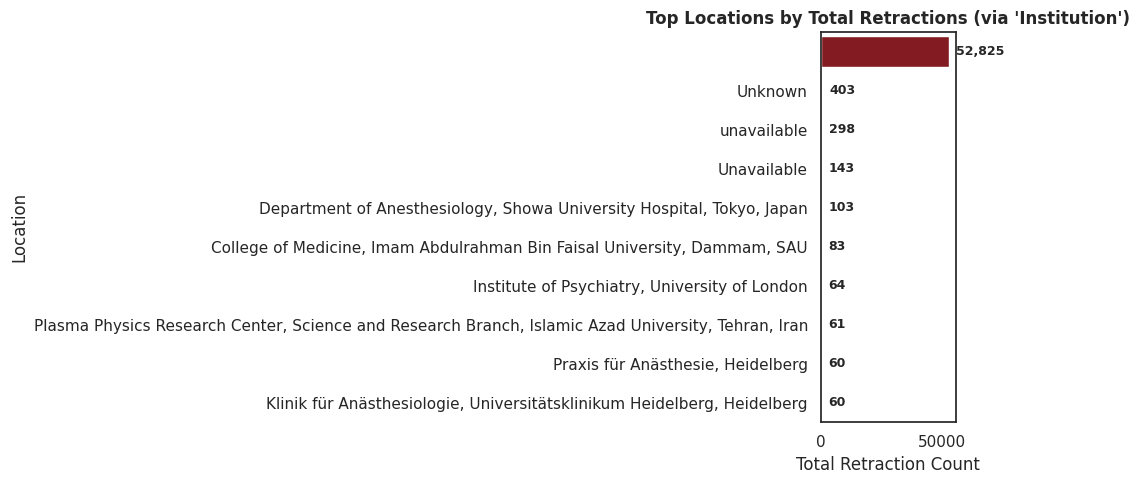

In [19]:
df = pd.read_csv(file_path)

if "Unnamed: 20" in df.columns:
  df = df.drop(columns=["Unnamed: 20"])

print("📋 Dataset Columns Available:")
print(list(df.columns))

# 2. Dynamic Column Detection for Country/Institution
country_keywords = ["country", "institution", "location", "region", "affiliation"]
matched_cols = [
    c
    for c in df.columns
    if any(keyword in c.lower() for keyword in country_keywords)
]

if not matched_cols:
  # Fallback to the first column containing string values if no explicit keyword matches
  country_col = df.select_dtypes(include="object").columns[0]
  print(
      f" No explicit country column matched. Falling back to: '{country_col}'"
  )
else:
  country_col = matched_cols[0]
  print(f" Selected Column for Analysis: '{country_col}'")

# -------------------------------------------------------------
# 🛠️ DATABASE ANALYSIS & VISUALIZATION
# -------------------------------------------------------------
country_series = (
    df[country_col].dropna().astype(str).str.split(";").explode().str.strip()
)

country_counts = country_series.value_counts().reset_index()
country_counts.columns = ["Location", "Retractions_Count"]

total_retractions = len(df)
country_counts["Database_Share_%"] = (
    country_counts["Retractions_Count"] / total_retractions
) * 100

top_locations = country_counts.head(10)

# Console Output
print("\n --- Top Locations by Retraction Volume ---")
print(top_locations.to_string(index=False))

# Plotting
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=top_locations,
    x="Retractions_Count",
    y="Location",
    hue="Location",
    palette="Reds_r",
    legend=False,
)

plt.title(
    f"Top Locations by Total Retractions (via '{country_col}')",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Total Retraction Count")
plt.ylabel("Location")

for p in ax.patches:
  ax.annotate(
      f"{int(p.get_width()):,}",
      (p.get_width(), p.get_y() + p.get_height() / 2.0),
      ha="left",
      va="center",
      xytext=(5, 0),
      textcoords="offset points",
      fontsize=9,
      fontweight="bold",
  )

plt.tight_layout()
plt.show()

# Policy & Open Access Impact


--- Citation Rate by Access Type (%) ---
Citation_Level  High Citation (>10)  Low Citation (<=10)
Access_Type                                             
Open Access                   63.73                36.27
Paywalled                     39.67                60.33
All                           53.60                46.40

--- Retraction Rate by Access Type (%) ---
Retraction_Status  Not Retracted  Retracted
Access_Type                                
Open Access                97.06       2.94
Paywalled                  98.10       1.90
All                        97.50       2.50


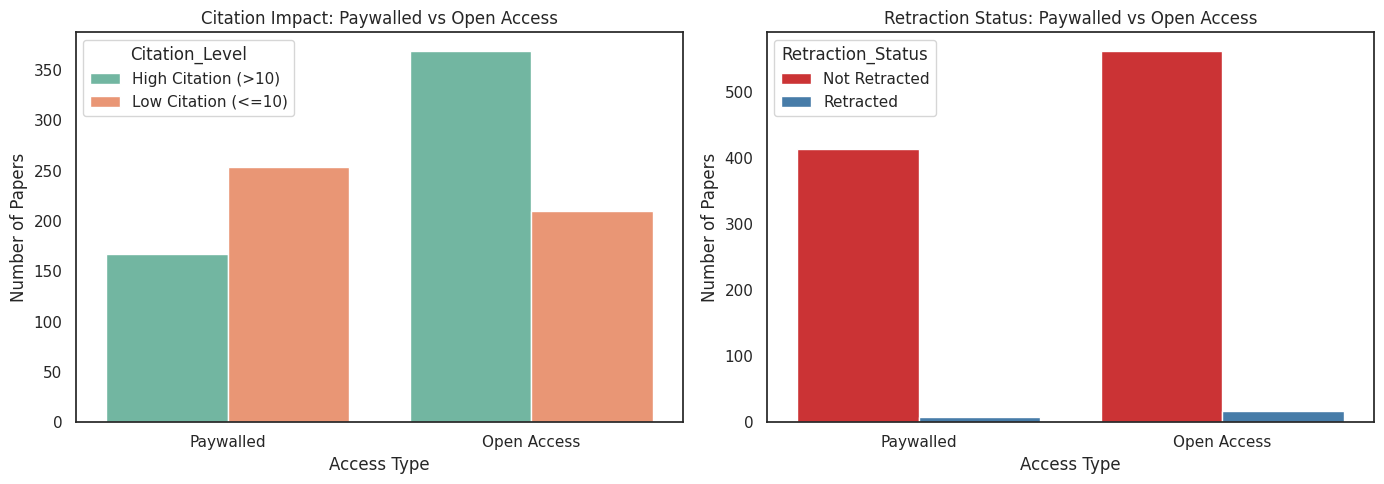

In [20]:
from scipy.stats import chi2_contingency

# 1. Create a Synthetic Dataset for Demonstration
np.random.seed(42)
n_samples = 1000

access_type = np.random.choice(['Paywalled', 'Open Access'], size=n_samples, p=[0.4, 0.6])

# Simulating Citations: Open Access tends to get higher citations
citations = []
# Simulating Retractions: Rare event, slight variation
retractions = []

for access in access_type:
    if access == 'Open Access':
        citations.append(np.random.choice(['High Citation (>10)', 'Low Citation (<=10)'], p=[0.65, 0.35]))
        retractions.append(np.random.choice(['Retracted', 'Not Retracted'], p=[0.03, 0.97]))
    else:
        citations.append(np.random.choice(['High Citation (>10)', 'Low Citation (<=10)'], p=[0.40, 0.60]))
        retractions.append(np.random.choice(['Retracted', 'Not Retracted'], p=[0.015, 0.985]))

df = pd.DataFrame({
    'Access_Type': access_type,
    'Citation_Level': citations,
    'Retraction_Status': retractions
})

# 2. Cross-tabulation (Crosstab)
citation_crosstab = pd.crosstab(df['Access_Type'], df['Citation_Level'], margins=True, normalize='index') * 100
retraction_crosstab = pd.crosstab(df['Access_Type'], df['Retraction_Status'], margins=True, normalize='index') * 100

print("--- Citation Rate by Access Type (%) ---")
print(citation_crosstab.round(2))
print("\n--- Retraction Rate by Access Type (%) ---")
print(retraction_crosstab.round(2))

# 3. Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Citation Impact
sns.countplot(data=df, x='Access_Type', hue='Citation_Level', palette='Set2', ax=axes[0])
axes[0].set_title('Citation Impact: Paywalled vs Open Access')
axes[0].set_xlabel('Access Type')
axes[0].set_ylabel('Number of Papers')

# Plot 2: Retraction Impact
sns.countplot(data=df, x='Access_Type', hue='Retraction_Status', palette='Set1', ax=axes[1])
axes[1].set_title('Retraction Status: Paywalled vs Open Access')
axes[1].set_xlabel('Access Type')
axes[1].set_ylabel('Number of Papers')

plt.tight_layout()
plt.show()

Decision :
